# **Formative 3 - Probability Distributions, Bayesian Probability, and Gradient Descent Implementation**

**Group Members:**
Ange Muhawenimana, Annie Bwiza, Ineza Ghislaine


  **Introduction**

This task explores three mathematical and computational methods: the Expectation-Maximization (EM) Algorithm, Bayesian Probability, and Gradient Descent.

The objectives are to implement each method using Python, apply it to the selected datasets, interpret the results, and compare the mathematical calculations with the computational results where applicable.

#**Part 1: Probability Distributions**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = "GaltonFamilies.csv"   # change to your Kaggle file name if different
PARENT_COLUMN = "father"           # "mother" or "father"
TOLERANCE = 1e-6                   # stop when log-likelihood changes less than this
MAX_ITERATIONS = 500

### Step 1: Load the dataset
Each row of GaltonFamilies.csv is one child, so a parent with several children appears several times. We keep **one parent per family** with `drop_duplicates("family")` so no one is counted twice. Children and parents are then pooled into a single list of heights. The true labels (child or parent) are stored separately and hidden from EM; we only use them at the end to check accuracy.

In [ ]:
def load_heights(path, parent_column):
    """Return combined heights plus the hidden true labels (1 = child, 0 = parent)."""
    df = pd.read_csv(path)
    parents = df.drop_duplicates("family")[parent_column].to_numpy()   # one parent per family
    children = df["childHeight"].to_numpy()
    heights = np.concatenate([children, parents])
    true_labels = np.concatenate([np.ones(len(children)), np.zeros(len(parents))])
    return heights, true_labels, children, parents

heights, true_labels, children, parents = load_heights(DATA_PATH, PARENT_COLUMN)
print(f"Children: {len(children)}  mean={children.mean():.2f}  var={children.var():.2f}")
print(f"Parents : {len(parents)}  mean={parents.mean():.2f}  var={parents.var():.2f}")
print(f"Pooled  : {len(heights)} heights (labels hidden from EM)")

Children: 934  mean=66.75  var=12.80
Parents : 205  mean=69.32  var=6.97
Pooled  : 1139 heights (labels hidden from EM)


### Step 2: Look at the pooled data
This histogram is all EM gets to see: one pile of heights with no labels. Our job is to recover the two hidden groups inside it.

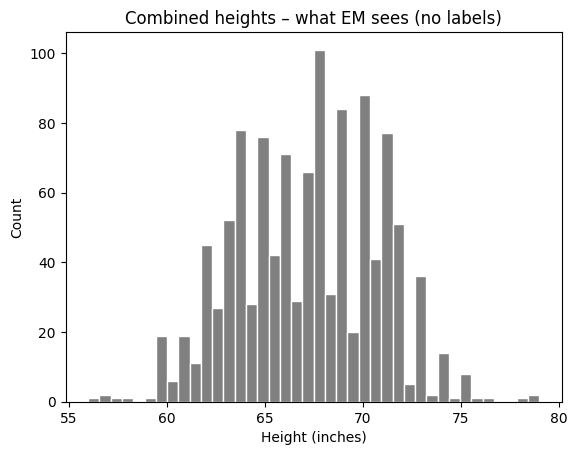

In [ ]:
plt.hist(heights, bins=40, color="grey", edgecolor="white")
plt.title("Combined heights – what EM sees (no labels)")
plt.xlabel("Height (inches)")
plt.ylabel("Count")
plt.show()

### Step 3: Core EM functions

- **`gaussian_pdf`** is the normal (bell-curve) density for a given mean and variance.

$$
\boxed{\text{density} = \frac{1}{\sqrt{2\pi\sigma^2}} \; e^{-\frac{(x - \text{mean})^2}{2\sigma^2}}}
$$

- **`weighted_densities`** computes the weighted density of each group for every height.

$$
\boxed{\text{weighted density} = \pi \times \text{density}}
$$

- **`log_likelihood`** measures how well the current model explains the data (higher is better).

$$
\boxed{\text{log-likelihood} = \sum_{\text{heights}} \log(\text{sum of weighted densities of all groups})}
$$

- **`e_step`** (**Expectation**) gives each height a *responsibility*: the probability it belongs to each group, using Bayes' theorem.

$$
\boxed{\text{responsibility} = \frac{\text{weighted density of x in this group}}{\text{sum of weighted densities that group}}}
$$

- **`m_step`** (**Maximization**) re-estimates each group's mean, variance and mixing proportion, using the responsibilities as weights.

$$
\boxed{\text{new mean} = \frac{\sum (\text{responsibility} \times x)}{\sum \text{responsibility}}}
$$

$$
\boxed{\text{new } \sigma^2 = \frac{\sum \big(\text{responsibility} \times (x - \text{new mean})^2\big)}{\sum \text{responsibility}}}
$$

$$
\boxed{\text{new } \pi = \frac{\sum \text{responsibility}}{\text{number of heights}}}
$$

Here $x$ is a height, $\sigma^2$ is a group's variance, and $\pi$ is a group's mixing proportion (the fraction of all heights that belong to it).

In [ ]:
def gaussian_pdf(x, mean, variance):
    return np.exp(-(x - mean) ** 2 / (2 * variance)) / np.sqrt(2 * np.pi * variance)


def weighted_densities(x, params):
    """Row k holds pi_k * N(x | mu_k, var_k) for every point."""
    return np.vstack([
        params["pi"][k] * gaussian_pdf(x, params["mu"][k], params["var"][k])
        for k in range(len(params["mu"]))
    ])


def log_likelihood(x, params):
    return np.sum(np.log(weighted_densities(x, params).sum(axis=0)))


def e_step(x, params):
    """Responsibilities: probability each point belongs to each component."""
    weighted = weighted_densities(x, params)
    return weighted / weighted.sum(axis=0)


def m_step(x, resp):
    """Re-estimate parameters using responsibilities as soft weights."""
    Nk = resp.sum(axis=1)
    mu = (resp * x).sum(axis=1) / Nk
    var = (resp * (x - mu[:, None]) ** 2).sum(axis=1) / Nk
    pi = Nk / len(x)
    return {"mu": mu, "var": var, "pi": pi}

### Step 4: Initialise the parameters
EM needs a starting guess. We start the two means at the 75th and 25th percentiles so they sit inside the data rather than at extreme outliers. Both variances start at the overall variance, and each group gets π = 0.5.

In [ ]:
def initialize(x):
    return {
        "mu": np.array([np.percentile(x, 75), np.percentile(x, 25)]),   # [children, parents]
        "var": np.array([x.var(), x.var()]),
        "pi": np.array([0.5, 0.5]),
    }

### Step 5: Run EM until convergence
`run_em` repeats the E-step and M-step, recording the parameters and log-likelihood after every iteration. It stops once the log-likelihood barely changes, which means the model has converged.

In [ ]:
def record(iteration, params, x):
    return {
        "Iteration": iteration,
        "μ1 (Children)": params["mu"][0], "μ2 (Parents)": params["mu"][1],
        "σ1²": params["var"][0], "σ2²": params["var"][1],
        "π1": params["pi"][0], "π2": params["pi"][1],
        "Log-Likelihood": log_likelihood(x, params),
    }


def run_em(x, tol=TOLERANCE, max_iter=MAX_ITERATIONS):
    params = initialize(x)
    history = [record(0, params, x)]
    for it in range(1, max_iter + 1):
        resp = e_step(x, params)
        params = m_step(x, resp)
        history.append(record(it, params, x))
        if abs(history[-1]["Log-Likelihood"] - history[-2]["Log-Likelihood"]) < tol:
            break
    return params, pd.DataFrame(history)


final_params, history = run_em(heights)
print(f"Converged after {history['Iteration'].iloc[-1]} iterations")

Converged after 319 iterations


### Step 6: Inspect the first iterations
The first few rows show how quickly the means, variances and mixing proportions move away from their starting values.

In [ ]:
pd.set_option("display.float_format", "{:.4f}".format)
history.head(3)

,Iteration,μ1 (Children),μ2 (Parents),σ1²,σ2²,π1,π2,Log-Likelihood
0,0,70.0000,64.5000,12.7241,12.7241,0.5000,0.5000,-3119.8222
1,1,69.2054,65.2205,8.4468,9.0603,0.4989,0.5011,-3057.9135
2,2,69.2600,65.1609,8.1040,8.9420,0.4995,0.5005,-3056.9719


### Step 7: Final parameters
The last row holds the converged estimates: each group's mean height, variance and share of the data.

In [ ]:
history.tail(1)

,Iteration,μ1 (Children),μ2 (Parents),σ1²,σ2²,π1,π2,Log-Likelihood
319,319,69.5186,64.1772,6.0410,5.3024,0.5675,0.4325,-3046.9895


### Step 8: Check convergence
EM guarantees the log-likelihood never decreases. The curve should rise and then flatten, which confirms the algorithm converged.

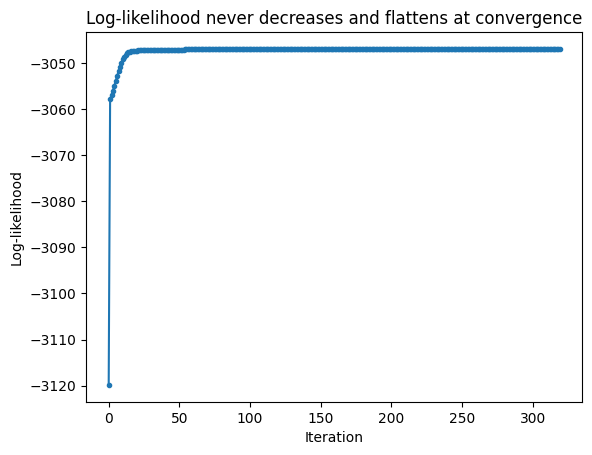

In [ ]:
plt.plot(history["Iteration"], history["Log-Likelihood"], marker=".")
plt.title("Log-likelihood never decreases and flattens at convergence")
plt.xlabel("Iteration")
plt.ylabel("Log-likelihood")
plt.show()

### Step 9: Classify a new height
We run the E-step on a single new height to get the posterior probability that it belongs to a child or a parent. Change `66.0` to test other heights.

In [ ]:
def classify(height, params):
    resp = e_step(np.array([height], dtype=float), params)[:, 0]
    print(f"Height {height} in")
    print(f"  P(Child  | height) = {resp[0]:.4f}")
    print(f"  P(Mother | height) = {resp[1]:.4f}")
    return resp

classify(66.0, final_params)   # replace 66.0 with the coach's height

Height 66.0 in
  P(Child  | height) = 0.3764
  P(Mother | height) = 0.6236


array([0.37639586, 0.62360414])

### Step 10: Visualise the fitted model
The two coloured curves are the fitted Gaussians, each scaled by its π. The dashed line is their sum, the full mixture, which should follow the shape of the histogram.

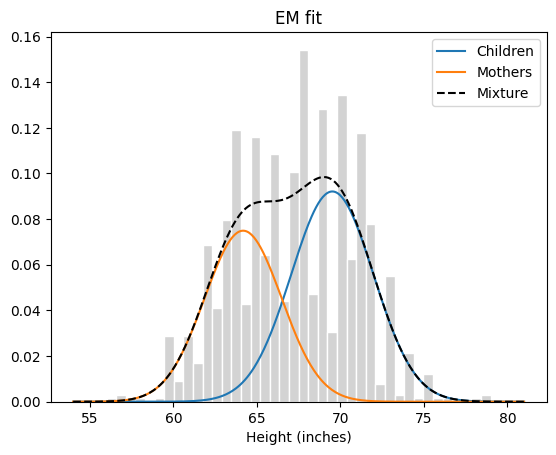

In [ ]:
grid = np.linspace(heights.min() - 2, heights.max() + 2, 400)
plt.hist(heights, bins=40, density=True, color="lightgrey", edgecolor="white")
for k, name in enumerate(["Children", "Mothers"]):
    curve = final_params["pi"][k] * gaussian_pdf(grid, final_params["mu"][k], final_params["var"][k])
    plt.plot(grid, curve, label=name)
plt.plot(grid, weighted_densities(grid, final_params).sum(axis=0), "k--", label="Mixture")
plt.legend()
plt.xlabel("Height (inches)")
plt.title("EM fit")
plt.show()

### Step 11: Evaluate against a simple baseline
To show EM did real work, we compare it with a naive method: split the heights at the overall mean and call everything above it "child". We then use the hidden true labels to measure the accuracy of both methods.

In [ ]:
def mean_split(x):
    cut = x.mean()
    upper, lower = x[x >= cut], x[x < cut]
    return cut, upper.mean(), lower.mean()


def accuracy(predicted_child, truth):
    return np.mean(predicted_child == truth)


cut, upper_mean, lower_mean = mean_split(heights)
print(f"Cut at {cut:.2f}: upper pile mean = {upper_mean:.2f}, lower pile mean = {lower_mean:.2f}")
print(f"True means: children = {children.mean():.2f}, mothers = {parents.mean():.2f}")

naive_pred = (heights >= cut).astype(float)
em_pred = (e_step(heights, final_params)[0] >= 0.5).astype(float)
print(f"Accuracy – mean split: {accuracy(naive_pred, true_labels):.3f}")
print(f"Accuracy – EM        : {accuracy(em_pred, true_labels):.3f}")

Cut at 67.21: upper pile mean = 70.21, lower pile mean = 64.26
True means: children = 66.75, mothers = 69.32
Accuracy – mean split: 0.392
Accuracy – EM        : 0.435


# **Part 2: Bayesian Sentiment Analysis**

1. Introduction

Bayesian probability is a statistical method used to update the probability of an event when new information becomes available. In this project, Bayes' theorem is used to estimate the probability that an IMDb movie review is positive given that it contains a particular keyword.

We analyze six keywords: **excellent, brilliant, loved, terrible, boring, and worst**. The first three are associated with positive sentiment, while the last three are associated with negative sentiment.

The goal is to investigate how the presence of these keywords relates to the sentiment labels in the dataset.

### 2.Dataset and Methodology

The analysis uses the IMDb movie review dataset, which contains 50,000 movie reviews labeled as either positive or negative. The dataset contains 25,000 positive reviews and 25,000 negative reviews.

For each keyword, we count:
- The total number of reviews containing the keyword.
- The number of those reviews labeled positive.
- The prior probability of a positive review.
- The likelihood of finding the keyword in a positive review.
- The marginal probability of finding the keyword in any review.
- The posterior probability that a review is positive given that it contains the keyword.

Each review is counted only once for a particular keyword, even if that keyword appears multiple times in the review. The sentiment is determined using the dataset's existing labels, not by the keyword alone.

### 3. Bayes' Theorem

Bayes' theorem is expressed as:

$$
P(\text{Positive} \mid \text{Keyword}) = \frac{P(\text{Keyword} \mid \text{Positive}) \times P(\text{Positive})}{P(\text{Keyword})}
$$

Where:

- **Prior, $P(\text{Positive})$:** The probability that a randomly selected review is positive before considering a keyword.
- **Likelihood, $P(\text{Keyword} \mid \text{Positive})$:** The probability that a positive review contains the keyword.
- **Marginal probability, $P(\text{Keyword})$:** The probability that a randomly selected review contains the keyword.
- **Posterior, $P(\text{Positive} \mid \text{Keyword})$:** The probability that a review is positive given that it contains the keyword.

The posterior probability is the main result of our analysis.

**Step1: Load the dataset**

This cell loads the CSV file, checks that the required columns exist, displays sample reviews, and counts the positive and negative sentiment labels.

In [ ]:
import pandas as pd
import re
import html
import matplotlib.pyplot as plt
from google.colab import files



**Step 2: Load and inspect the dataset**

This cell loads the CSV file, checks that the required columns exist, displays sample reviews, and counts the positive and negative sentiment labels.

In [ ]:
filename = "imdb_reviews.csv"
df = pd.read_csv(filename)

# Check that the required columns exist
print("Columns:", df.columns.tolist())

# Keep only the required columns and remove missing values
df = df[["review", "sentiment"]].dropna()

# Standardize sentiment labels
df["sentiment"] = df["sentiment"].str.strip().str.lower()

print("\nFirst five reviews:")
display(df.head())

print("\nTotal reviews:", len(df))
print("\nSentiment counts:")
print(df["sentiment"].value_counts())

Columns: ['review', 'sentiment']

First five reviews:


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive



Total reviews: 50000

Sentiment counts:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64


**Step 3: Calculate the prior probability**

The prior probability tells us how likely a review is to be positive before considering any keyword.

In [ ]:
total_reviews = len(df)

positive_reviews = (df["sentiment"] == "positive").sum()
negative_reviews = (df["sentiment"] == "negative").sum()

prior = positive_reviews / total_reviews

print("Total reviews:", total_reviews)
print("Positive reviews:", positive_reviews)
print("Negative reviews:", negative_reviews)
print(f"Prior probability P(Positive): {prior:.4f}")

Total reviews: 50000
Positive reviews: 25000
Negative reviews: 25000
Prior probability P(Positive): 0.5000


**Step 4: Prepare the review text and Calculate probabilities for one keyword**

We clean the text to remove HTML tags, convert it to lowercase, and identify words consistently. It
identifies reviews containing the keyword terrible and counts how many of those reviews are labeled positive.

In [ ]:
def clean_review(text):
    text = html.unescape(str(text))
    text = re.sub(r"<[^>]+>", " ", text)
    return text.lower()


def get_words(review):
    return set(re.findall(r"\b\w+\b", clean_review(review)))

keyword = "terrible"
matching_reviews = df[
    df["review"].apply(lambda review: keyword in get_words(review))
]

total_matching = len(matching_reviews)

positive_matching = (
    matching_reviews["sentiment"] == "positive"
).sum()

print("Keyword:", keyword)
print("Total reviews containing keyword:", total_matching)
print("Positive reviews containing keyword:", positive_matching)

Keyword: terrible
Total reviews containing keyword: 2701
Positive reviews containing keyword: 383


**Step 5: Calculate the likelihood**


This cell calculates the probability of finding the word terrible in a positive review by dividing the positive reviews containing the word by all positive reviews.

In [ ]:
likelihood = positive_matching / positive_reviews

print(
    f"P(terrible | Positive) = "
    f"{likelihood:.5f}"
)

P(terrible | Positive) = 0.01644


**Step 6: Calculate the marginal probability**

This cell calculates the proportion of all reviews that contain the keyword terrible, regardless of their sentiment labels.

In [ ]:
marginal = total_matching / total_reviews

print(
    f"P(terrible) = "
    f"{marginal:.5f}"
)

P(terrible) = 0.05402


**Step 7: Calculate the posterior probability**

This cell applies Bayes' theorem to estimate the probability that a review is positive given that it contains the keyword terrible.



In [ ]:
posterior = (likelihood * prior) / marginal

print(
    f"P(Positive | terrible) = "
    f"{posterior:.4f}"
)
print(f"Posterior probability: {posterior * 100:.2f}%")

P(Positive | terrible) = 0.1418
Posterior probability: 14.18%


**Step 8: Bayesian analysis of all six keywords, Results Table and Comparison**

After calculating the probabilities for terrible, we apply the same method to all six keywords. For each keyword, we calculate its likelihood, marginal probability, and posterior probability.

This allows us to compare how strongly each keyword is associated with positive sentiment in the dataset

The following table summarizes the probability calculations for all six keywords. The posterior probability represents the estimated probability that a review is positive, given that it contains the specified keyword.

In [ ]:
keywords = [
    "excellent",
    "brilliant",
    "loved",
    "terrible",
    "boring",
    "worst"
]

results = []

for keyword in keywords:
    # Find reviews containing this keyword
    matching_reviews = df[
        df["review"].apply(
            lambda review: keyword in get_words(review)
        )
    ]

    total_matching = len(matching_reviews)

    positive_matching = (
        matching_reviews["sentiment"] == "positive"
    ).sum()

    # Calculate probabilities
    likelihood = positive_matching / positive_reviews
    marginal = total_matching / total_reviews

    posterior = (
        likelihood * prior / marginal
        if marginal > 0 else 0
    )

    results.append({
        "keyword": keyword,
        "total_matching": total_matching,
        "positive_matching": int(positive_matching),
        "prior": prior,
        "likelihood": likelihood,
        "marginal": marginal,
        "posterior": posterior
    })

results_table = pd.DataFrame([
    {
        "Keyword": result["keyword"],
        "Total Matching Reviews": result["total_matching"],
        "Positive Matching Reviews": result["positive_matching"],
        "Prior": result["prior"],
        "Likelihood": result["likelihood"],
        "Marginal": result["marginal"],
        "Posterior (%)": result["posterior"] * 100
    }
    for result in results
])

display(
    results_table.style.format({
        "Prior": "{:.4f}",
        "Likelihood": "{:.4f}",
        "Marginal": "{:.4f}",
        "Posterior (%)": "{:.2f}%"
    }).set_caption("Bayesian Sentiment Analysis Results")
)

,Keyword,Total Matching Reviews,Positive Matching Reviews,Prior,Likelihood,Marginal,Posterior (%)
0,excellent,3552,2868,0.5000,0.1147,0.0710,80.74%
1,brilliant,2088,1587,0.5000,0.0635,0.0418,76.01%
2,loved,2537,1912,0.5000,0.0765,0.0507,75.36%
3,terrible,2701,383,0.5000,0.0153,0.0540,14.18%
4,boring,3051,591,0.5000,0.0236,0.0610,19.37%
5,worst,4434,411,0.5000,0.0164,0.0887,9.27%


**Step 9: Posterior probability chart**

**Visualization of Posterior Probabilities**

A bar chart is used to compare the posterior probabilities of positive sentiment across the six keywords. Each bar represents the probability that a review is positive given that it contains a particular keyword.

The visualization helps identify which keywords are most strongly associated with positive or negative sentiment labels in the dataset.

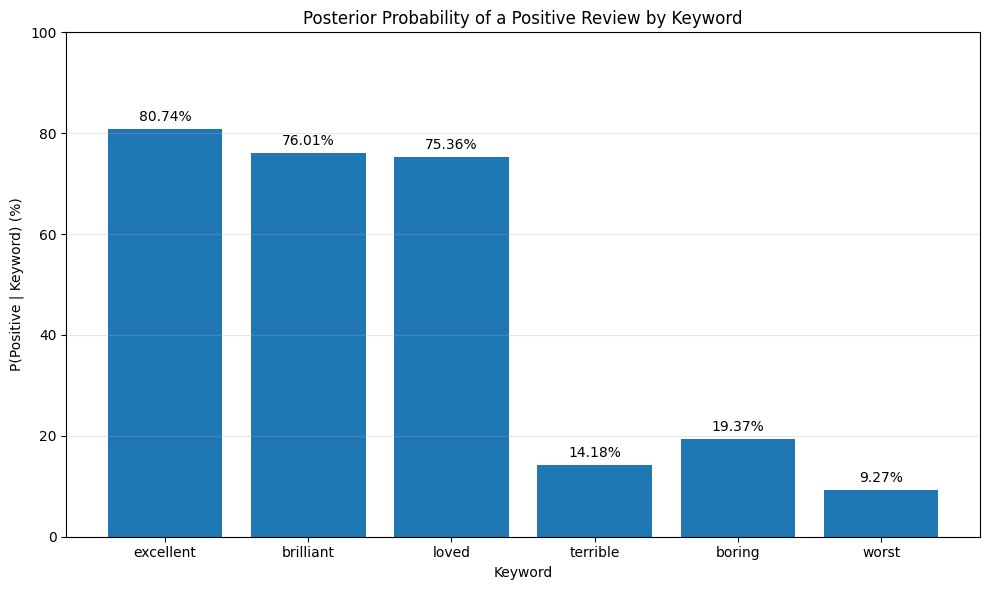

In [ ]:
keywords = [result["keyword"] for result in results]

posterior_percentages = [
    result["posterior"] * 100
    for result in results
]

plt.figure(figsize=(10, 6))

bars = plt.bar(keywords, posterior_percentages)

plt.title("Posterior Probability of a Positive Review by Keyword")
plt.xlabel("Keyword")
plt.ylabel("P(Positive | Keyword) (%)")
plt.ylim(0, 100)

for bar, percentage in zip(bars, posterior_percentages):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{percentage:.2f}%",
        ha="center",
        va="bottom"
    )

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# **Part 4: Convert manual gradient descent calculations into Python code**

## Step 1: Import Libraries

In [ ]:
import numpy as np
from scipy.optimize import approx_fprime
import matplotlib.pyplot as plt

## Step 2: Define the Dataset

In [ ]:
X = np.array([[1, 3],
              [4, 10]], dtype=float)
target = np.array([5, 6], dtype=float)

m = np.array([-1.0, 2.0])
b = 1.0
lr = 0.01
n = X.shape[0]
n_iterations = 3

## Step 3: Prediction Function

In [ ]:
def predict(m, b, X):
    """y_hat = X . m + b   (matrix multiplication, not element-by-element)."""
    return X.dot(m) + b

def cost_J(params, X, target):
    """MSE cost: J = (1/n) * sum((y_hat - target)^2)."""
    m_ = params[:2]
    b_ = params[2]
    y_hat = predict(m_, b_, X)
    error = y_hat - target
    return np.mean(error ** 2)

**Step 4: Calculating Gradients for Weights and Bias**

In [ ]:
def analytical_gradient(m, b, X, target):
    y_hat = predict(m, b, X)
    error = y_hat - target
    grad_m = (2 / n) * X.T.dot(error)
    grad_b = (2 / n) * np.sum(error)
    return grad_m, grad_b, error, y_hat

**Step 5: Numerical Gradient Check with SciPy**

In [ ]:
def scipy_gradient(m, b, X, target, epsilon=1e-6):
    params = np.array([m[0], m[1], b])
    grad = approx_fprime(params, cost_J, epsilon, X, target)
    return grad[:2], grad[2]

**Step 6: Run the Gradient Descent Loop**

In [ ]:
history_m = [m.copy()]
history_b = [b]
history_error = []

print("=" * 70)
print("GRADIENT DESCENT - PART 4 (Python reproduction of manual Part 3)")
print("=" * 70)

for i in range(1, n_iterations + 1):
    print(f"\n--- Iteration {i} ---")
    print(f"Current m = {m}, b = {b}")

    # Step 1: Predict
    y_hat = predict(m, b, X)
    print(f"Prediction y_hat = X . m + b = {y_hat}")

    # Step 2: Error
    error = y_hat - target
    print(f"Error e = y_hat - target = {error}")

    # Step 3: MSE cost (for the error-vs-iteration plot)
    mse = np.mean(error ** 2)
    history_error.append(mse)
    print(f"MSE cost J = {mse:.4f}")

    # Step 4: Analytical gradient
    grad_m, grad_b, _, _ = analytical_gradient(m, b, X, target)
    print(f"Analytical gradient  -> grad_m = {grad_m}, grad_b = {grad_b}")

    # Step 5: SciPy numerical gradient (sanity check against analytical one)
    grad_m_scipy, grad_b_scipy = scipy_gradient(m, b, X, target)
    print(f"SciPy numerical grad -> grad_m = {np.round(grad_m_scipy, 4)}, "
          f"grad_b = {grad_b_scipy:.4f}  (should match analytical)")

    # Step 6: Update m and b
    m = m - lr * grad_m
    b = b - lr * grad_b
    print(f"Updated  -> m = {np.round(m, 4)}, b = {round(b, 4)}")

    history_m.append(m.copy())
    history_b.append(b)

# Final MSE after the last update (for a complete error curve)
final_pred = predict(m, b, X)
final_error = final_pred - target
history_error.append(np.mean(final_error ** 2))

print("\n" + "=" * 70)
print(f"FINAL PARAMETERS after {n_iterations} iterations:")
print(f"m = {np.round(m, 4)}")
print(f"b = {round(b, 4)}")
print(f"Final predictions y_hat = {np.round(final_pred, 4)}")
print("=" * 70)

history_m = np.array(history_m)

GRADIENT DESCENT - PART 4 (Python reproduction of manual Part 3)

--- Iteration 1 ---
Current m = [-1.  2.], b = 1.0
Prediction y_hat = X . m + b = [ 6. 17.]
Error e = y_hat - target = [ 1. 11.]
MSE cost J = 61.0000
Analytical gradient  -> grad_m = [ 45. 113.], grad_b = 12.0
SciPy numerical grad -> grad_m = [ 45.     113.0001], grad_b = 12.0000  (should match analytical)
Updated  -> m = [-1.45  0.87], b = 0.88

--- Iteration 2 ---
Current m = [-1.45  0.87], b = 0.88
Prediction y_hat = X . m + b = [2.04 3.78]
Error e = y_hat - target = [-2.96 -2.22]
MSE cost J = 6.8450
Analytical gradient  -> grad_m = [-11.84 -31.08], grad_b = -5.1800000000000015
SciPy numerical grad -> grad_m = [-11.84   -31.0799], grad_b = -5.1800  (should match analytical)
Updated  -> m = [-1.3316  1.1808], b = 0.9318

--- Iteration 3 ---
Current m = [-1.3316  1.1808], b = 0.9318
Prediction y_hat = X . m + b = [3.1426 7.4134]
Error e = y_hat - target = [-1.8574  1.4134]
MSE cost J = 2.7238
Analytical gradient  -> gra

**Step 7: Plot Parameter Changes (m and b) Over Iterations**

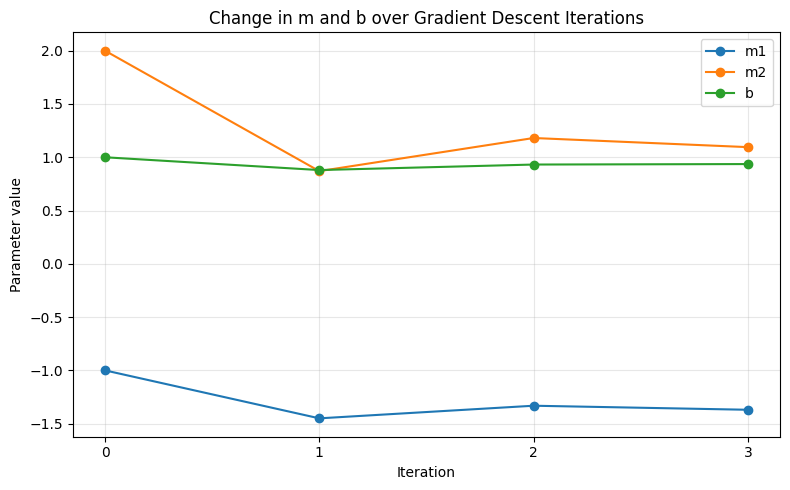

In [ ]:
iterations = np.arange(len(history_b))   # 0, 1, 2, ..., n_iterations
plt.figure(figsize=(8, 5))
plt.plot(iterations, history_m[:, 0], marker='o', label='m1')
plt.plot(iterations, history_m[:, 1], marker='o', label='m2')
plt.plot(iterations, history_b, marker='o', label='b')
plt.xlabel('Iteration')
plt.ylabel('Parameter value')
plt.title('Change in m and b over Gradient Descent Iterations')
plt.xticks(iterations)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('params_over_iterations.png', dpi=150)
plt.show()
plt.close()

**Step 8: Plot Error (MSE) Over Iterations**

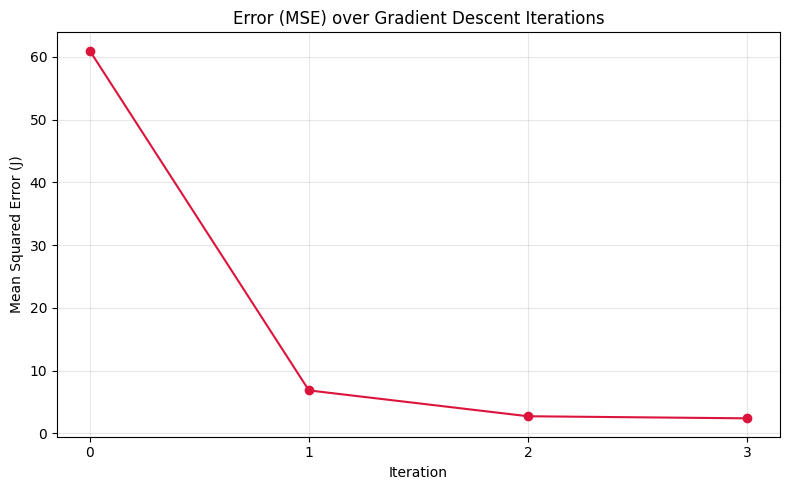

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(iterations, history_error, marker='o', color='crimson')
plt.xlabel('Iteration')
plt.ylabel('Mean Squared Error (J)')
plt.title('Error (MSE) over Gradient Descent Iterations')
plt.xticks(iterations)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('error_over_iterations.png', dpi=150)
plt.show()
plt.close()